# Animation
The purpose of this Jupyter Notebook is to present a simple step-by-step example of how to create an animation.

## 1 What should I know before I start?
 - How to implement functions in Python.
 - How to deal with arrays and mathematical functions in `numpy`.
 - How to generate grafics with `pyplot` from `matplotlib`.

## 2 Packages
The following packages are used to display images:

In [1]:
from IPython.display import Image, HTML

## 3 What is an animation?
An animation consits of a sequence of images.
Each single image is called a frame.
Consecutive images are shown with a certain frequency.
This frequency is called frame rate and is specified in hertz.

<b>ToDo:</b> Insert a picture for better explanation!

## 4 A simple example: The sigmoid function

<div class="alert alert-block alert-warning">
    
<b>Example</b>

Let us consider the so called sigmoid functions
    
$$
      f(x) = \frac{1}{1+\mathrm{e}^{- c \, x}}, \quad x \in [-5,5] \, .
$$

To be more presicly, we consider the family of functions for $c \in \left\{ 1,2,3, \ldots , 9\right\}$.
Our goal is to generate an animation for this family of functions.

</div>

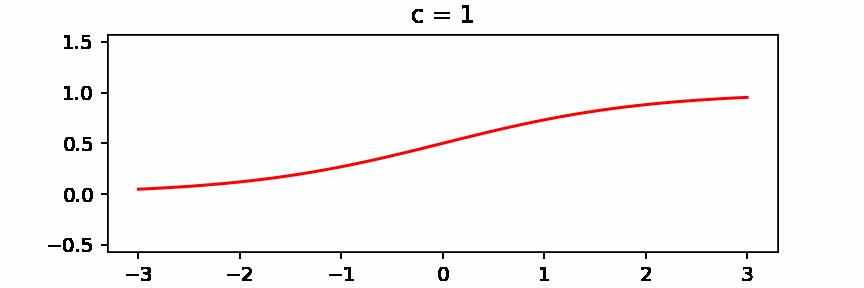

In [2]:
Image('images/24-animation-sigmoid.gif', width=864, height=288)

## 5 Build the animation
The animation is bulit step-by-step.

### 5.1 Create a figure
First, a figure is generated.
Every frame of the animation will be generated inside the same figure.
The variable `fig` will be used as a global variable.
At the moment the figure should not be displayed.
Calling the function [`matplotlib.pyplot.close()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.pyplot.close.html) will hide the figure.

In [3]:
import matplotlib.pyplot as plt

fig = plt.figure(figsize=(6, 2),dpi=144)
plt.close(fig)

### 5.2 Animation concept
The idea is to implement a function which generates a single frame each time the function is called.
A totally clearing of the plot and a complete redraw is done for each frame.


### 5.3 The `frame()` function
Now we define the so called `frame()` function.
This function has one input argument $c$.
Calling this function once will plot a single sigmoid function corresponding to the input value $c$.
In general, a sequence of values for the input argument $c$ will generate a sequence of images.

At the beginning of the `frame()` function the figure is cleared.
It's important to recognize that we always use the already generated figure `fig` for each frame.
The title and the axis are set accordingly and then the sigmoid function with parameter $c$ is ploted to the axes of the figure.

In [4]:
import numpy as np

def frame(c):
    
    # clear figure
    fig.clf()
    
    # get axis of figure
    ax = fig.gca()
    
    # set axis properties
    ax.set_title('c = '+str(c))
    ax.axis([-3.0,3.0,-0.5,1.5])
    ax.axis('equal')
    
    # plot
    x = np.linspace(-3.0,3.0)
    f = 1.0/(1.0 + np.exp(-c*x))
    ax.plot(x,f,'-r')

### 5.4 Generate animation object
The animation object is generated by [`FuncAnimation()`](https://matplotlib.org/stable/api/_as_gen/matplotlib.animation.FuncAnimation.html) from `matplotlib.animation` using the already generated figure `fig`, the function `frame()` and a sequence of values $1,2,3,\ldots,9$ for the parameter $c$.
The variable `ani` will be used as a global variable for the animation object.

In [5]:
import matplotlib.animation
ani = matplotlib.animation.FuncAnimation(fig, func=frame, frames=range(1,10))

## 6 Display animation in Juypter Notebook
The function `to_jshtml()` represents the animation object as Java Script code embedded in HTML.
This can be directly integrated in the Jupyter Notebook with the function `HTML()` form `IPython.display`.

In [6]:
display(HTML(ani.to_jshtml()))

## 7 Save animation as a movie file
An animation may be saved as a movie in a file by drawing every frame.
A list of all installed writers on your system can be generated.

In [ ]:
print(matplotlib.animation.writers.list())

A widely used data format to store animations are `.gif` files which can be generated with the `pillow` writer. 

In [ ]:
ani.save('24-animation-sigmoid.gif', writer='pillow')

If no apropriate writer is installed you may install ImageMagick.
ImageMagick is free software which runs on most operating systems.

In [ ]:
# Instalation of ImageMagick, see https://imagemagick.org/index.php
#
# Windows
# see https://towardsdatascience.com/quick-code-exporting-matplotlib-animations-49cd0ecf32ba
#
# Google Colab
# !apt install imagemagick
#
# Mac OS
# !brew install imagemagick

## Literature
- https://youtu.be/3IsiOYbdzpU